# Movies metadata

## Imports

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import ast
import csv, io

In [2]:
root = '../data'

## Read file

In [3]:
# fix the 6 rows that were wrongfully split
with open(root + '/movies_metadata.csv', encoding='utf-8', newline='') as f:
    rows = list(csv.reader(f))

# merge records that were split by a line break in overview
fixed = [rows[0]]
bad_rows = 0 
for row in rows[1:]:
    if len(fixed[-1]) < len(rows[0]):          # previous row is incomplete
        first_half = fixed.pop()
        row = first_half[:-1] + [first_half[-1] + ' ' + row[0].strip()] + row[1:]
        bad_rows += 1
    fixed.append(row)

# let pandas read the repaired data
buf = io.StringIO()
csv.writer(buf).writerows(fixed)
buf.seek(0)

mm = pd.read_csv(buf)

# mm = pd.read_csv(root + '/movies_metadata.csv')
display(mm.head())
print(f"There were {bad_rows} movies that were split and needed to be fixed")

,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,...,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
0,False,"{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",http://toystory.disney.com/toy-story,862,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",...,1995-10-30,373554033,81.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Toy Story,False,7.7,5415
1,False,NaN,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",NaN,8844,tt0113497,en,Jumanji,When siblings Judy and Peter discover an encha...,...,1995-12-15,262797249,104.0,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso...",Released,Roll the dice and unleash the excitement!,Jumanji,False,6.9,2413
2,False,"{'id': 119050, 'name': 'Grumpy Old Men Collect...",0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",NaN,15602,tt0113228,en,Grumpier Old Men,A family wedding reignites the ancient feud be...,...,1995-12-22,0,101.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Still Yelling. Still Fighting. Still Ready for...,Grumpier Old Men,False,6.5,92
3,False,NaN,16000000,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",NaN,31357,tt0114885,en,Waiting to Exhale,"Cheated on, mistreated and stepped on, the wom...",...,1995-12-22,81452156,127.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Friends are the people who let you be yourself...,Waiting to Exhale,False,6.1,34
4,False,"{'id': 96871, 'name': 'Father of the Bride Col...",0,"[{'id': 35, 'name': 'Comedy'}]",NaN,11862,tt0113041,en,Father of the Bride Part II,Just when George Banks has recovered from his ...,...,1995-02-10,76578911,106.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Just When His World Is Back To Normal... He's ...,Father of the Bride Part II,False,5.7,173


There were 3 movies that were split and needed to be fixed


In [4]:
# the DtypeWarning flags column 10 (popularity). We therefore inspect which types it holds
display(mm['popularity'].map(type).value_counts())

# Find the values that cannot be read as numbers, no longer needed
# popularity_num = pd.to_numeric(mm['popularity'], errors='coerce')
# not_numeric = mm[popularity_num.isna() & mm['popularity'].notna()]
# display(not_numeric[['id', 'title', 'popularity']])

# Convert to float so equal values compare as equal, no longer needed
# mm['popularity'] = popularity_num

popularity
<class 'float'>    45463
Name: count, dtype: int64

In [5]:
# inspect the number of rows and columns
print(f"There are {mm.shape[0]} rows and {mm.shape[1]} columns")

# find potential duplicate rows and keep first
print(f'Number of duplicate copies that can be removed: {mm.duplicated().sum()}') 

There are 45463 rows and 24 columns
Number of duplicate copies that can be removed: 17


## id

In [6]:
# check for na values
print(f"Nr of rows with no id: {mm[mm.id.isna()].shape[0]}")

Nr of rows with no id: 0


In [7]:
# check whether id is unique
id_vc = mm.id.value_counts()
print(f'There are {mm.id.shape[0] - len(mm.id.unique())} duplicate rows, among which the highest number of dublicates for one id is {id_vc.values[0].item()} which occurs {(id_vc == id_vc.iloc[0]).sum().item()} time ')


There are 30 duplicate rows, among which the highest number of dublicates for one id is 3 which occurs 1 time 


In [8]:
# inspect duplicate ids
def get_duplicates(df, column_name, freq=1):
    counts = df.groupby(column_name).size()
    duplicate = counts[counts > freq].index
    duplicates = df[df[column_name].isin(duplicate)].sort_values(by=[column_name])
    return duplicates

duplicate_ids = get_duplicates(mm, 'id')

In [9]:
# inspect the edge case of three rows
triple = get_duplicates(mm, 'id', 2)

differs = triple.groupby('id').nunique(dropna=False).gt(1).any()
diff_cols = differs[differs].index.tolist()

if diff_cols:
    display(triple[['id'] + diff_cols])
else:
    print(f'The {len(triple)} rows for triplet ids are identical in every column')

The 3 rows for triplet ids are identical in every column


In [10]:
def column_differs(df, column_name):
    differs = df.groupby(column_name).nunique(dropna=False).gt(1)
    differs_summary = differs.apply(lambda row: list(row.index[row]), axis=1)
    print(f'Fully identical duplicates: {(differs_summary.str.len() == 0).sum()} of {len(differs_summary)}')
    display(differs.sum()[lambda s: s > 0].rename('differing_columns'))   # how many ids differ in each column

# find the rows with duplicate id, but different values and list the differences
column_differs(duplicate_ids, 'id')

Fully identical duplicates: 16 of 29


popularity    13
vote_count     2
Name: differing_columns, dtype: int64

In [11]:
# check the relation between index, votes and popularity
# per duplicate id: compare the first row (lowest index) with the last row (highest index)
dup_sorted = duplicate_ids.sort_index().assign(
    popularity=lambda d: pd.to_numeric(d['popularity'], errors='coerce')
)

grouped = dup_sorted.groupby('id')[['popularity', 'vote_count']]
labels = {-1: 'first higher', 0: 'equal', 1: 'last higher'}
change = np.sign(grouped.last() - grouped.first()).replace(labels).astype(pd.CategoricalDtype(labels.values()))

print('Statistics for duplicate ids')
display(pd.crosstab(
    change['popularity'].cat.rename_categories(lambda c: f'popularity {c}'),
    change['vote_count'].cat.rename_categories(lambda c: f'votes {c}'),
    margins=True, margins_name='total', dropna=False,
))


Statistics for duplicate ids


vote_count,votes first higher,votes equal,votes last higher,total
popularity,,,,
popularity first higher,0,7,2,9
popularity equal,0,16,0,16
popularity last higher,0,4,0,4
total,0,27,2,29


## title

In [12]:
# check for na values
print(f"Number of titles with no value: {mm[mm.title.isna()].shape[0]}")

Number of titles with no value: 0


In [42]:
# discover formatting errors
t = mm.title.dropna()
print("Nr of rows containing leading spaces:", (t != t.str.strip()).sum())                                  
print("Nr of rows containing double spaces:", t.str.contains('  ').sum())                             
print("Nr of rows that differ by case:", t.str.lower().duplicated().sum() - t.duplicated().sum())    
 
# find differences in rows where the only difference in title is case
mm_lowercase_title = mm.copy(deep=True)
mm_lowercase_title["title"] = mm.title.str.lower()
duplicate_lower = get_duplicates(mm_lowercase_title, 'title')
column_differs(duplicate_lower, 'title')

Nr of rows containing leading spaces: 0
Nr of rows containing double spaces: 22
Nr of rows that differ by case: 50
Fully identical duplicates: 11 of 2370


adult                       1
belongs_to_collection     246
budget                   1080
genres                   2189
homepage                  748
id                       2347
imdb_id                  2347
original_language        1043
original_title           1010
overview                 2341
popularity               2359
poster_path              2347
production_companies     2252
production_countries     1841
release_date             2347
revenue                   943
runtime                  2310
spoken_languages         1654
status                     56
tagline                  1879
video                       2
vote_average             2300
vote_count               2306
Name: differing_columns, dtype: int64

In [14]:
# inspect movie name in general
mm_title_described = mm.title.describe()
display(mm_title_described)
print(f'There are {mm_title_described['count'] - mm_title_described['unique']} duplicate rows among which the highest frequency is {mm_title_described['freq']}')

count          45463
unique         42279
top       Cinderella
freq              11
Name: title, dtype: object

There are 3184 duplicate rows among which the highest frequency is 11


In [15]:
# look into the most frequent title Cinderella
display(mm[mm.title == 'Cinderella'])

,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,...,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
993,False,"{'id': 55419, 'name': 'Cinderella Collection',...",2900000,"[{'id': 10751, 'name': 'Family'}, {'id': 14, '...",http://movies.disney.com/cinderella-1950,11224,tt0042332,en,Cinderella,Cinderella has faith her dreams of a better li...,...,1950-03-04,263591415,74.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,The greatest love story ever told.,Cinderella,False,6.8,1760
13076,False,NaN,0,"[{'id': 10770, 'name': 'TV Movie'}, {'id': 107...",NaN,42884,tt0128996,en,Cinderella,Updated version of the classic Rodgers and Ham...,...,1997-11-02,0,88.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Cinderella,False,6.1,28
23506,False,NaN,0,"[{'id': 14, 'name': 'Fantasy'}, {'id': 18, 'na...",NaN,92349,tt0003772,en,Cinderella,Based on Charles Perrault's fairy tale: Cinder...,...,1914-12-28,0,52.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Cinderella,False,5.4,7
23517,False,NaN,0,"[{'id': 16, 'name': 'Animation'}, {'id': 10751...",NaN,105875,tt0910852,en,Cinderella,"Cinderella, the beautiful and kind-hearted rag...",...,2002-08-06,0,48.0,"[{'iso_639_1': 'af', 'name': 'Afrikaans'}]",Released,The version children love!,Cinderella,False,6.0,2
28390,False,NaN,0,"[{'id': 10751, 'name': 'Family'}, {'id': 10770...",http://www.betafilm.com/en/product/do/detail.h...,261985,tt1781790,en,Cenerentola,Once upon a time in post-war Rome: 13-year old...,...,2011-10-30,0,180.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Cinderella,False,5.3,9
28663,False,NaN,95000000,"[{'id': 10749, 'name': 'Romance'}, {'id': 14, ...",http://movies.disney.com/cinderella,150689,tt1661199,en,Cinderella,"When her father unexpectedly passes away, youn...",...,2015-03-12,543514353,105.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Midnight is just the beginning.,Cinderella,False,6.7,2426
34252,False,NaN,0,"[{'id': 35, 'name': 'Comedy'}, {'id': 10751, '...",NaN,42651,tt0168269,ru,Zolushka,"Based on a classic fairytale ""Cinderella"" bril...",...,1947-11-28,0,80.0,"[{'iso_639_1': 'ru', 'name': 'Pусский'}]",Released,NaN,Cinderella,False,4.8,5
35590,False,NaN,0,"[{'id': 18, 'name': 'Drama'}, {'id': 10749, 'n...",NaN,44459,tt0129672,en,Cinderella,The first of three TV-versions of the classic ...,...,1957-03-31,0,77.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Cinderella,False,5.9,5
35592,False,NaN,0,[],NaN,289673,tt0218891,en,Cinderella,Cinderella (named Zezolla) and her family live...,...,2000-01-01,0,90.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Cinderella,False,5.6,5
41071,False,NaN,0,"[{'id': 14, 'name': 'Fantasy'}, {'id': 27, 'na...",NaN,114108,tt0000230,fr,Cendrillon,A fairy godmother magically turns Cinderella's...,...,1899-10-01,0,5.0,"[{'iso_639_1': 'xx', 'name': 'No Language'}]",Released,NaN,Cinderella,False,5.5,19


## original title

In [16]:
# inspect movie name in general
mm_original_title_described = mm.original_title.describe()
print(f"Number of original titles with no value: {mm[mm.original_title.isna()].shape[0]}")
display(mm_original_title_described)
print(f'There are {mm_original_title_described['count'] - mm_original_title_described['unique']} duplicate rows among which the highest frequency is {mm_original_title_described['freq']}')

Number of original titles with no value: 0


count                   45463
unique                  43371
top       Alice in Wonderland
freq                        8
Name: original_title, dtype: object

There are 2092 duplicate rows among which the highest frequency is 8


## release date

In [17]:
display(f"The released date ranges from {mm.release_date.sort_values().iloc[0] } to {mm.release_date.sort_values(ascending=False).iloc[1]}")

# find the release dates that are not on the format YYYY-MM-DD
parsed = pd.to_datetime(mm.release_date, format='%Y-%m-%d', errors='coerce')
print("Release date values that are not on the format YYYY-MM-DD:")
display(mm.loc[parsed.isna(), 'release_date'].value_counts(dropna=False))

print(f"There are {mm.release_date.isna().sum()} ({mm.release_date.isna().mean():.1%}) columns with missing values for release date")
# verify whether it is the three rows that will be removed
# mm[mm.release_date.isin(['87', '1', '12', '22'])]

'The released ate ranges from 1874-12-09 to 2018-12-31'

Release date values that are not on the format YYYY-MM-DD:


release_date
NaN    84
Name: count, dtype: int64

There are 84 (0.2%) columns with missing values for release date


## runtime

count    45206.000000
mean        94.127572
std         38.406803
min          0.000000
25%         85.000000
50%         95.000000
75%        107.000000
max       1256.000000
Name: runtime, dtype: float64

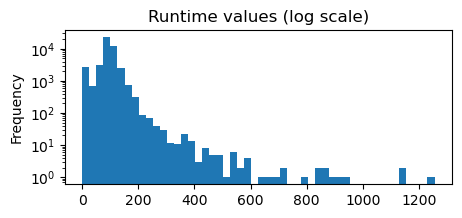

There are 257 (0.6%) columns with missing value for runtime
There are 1558 (3.4%) columns with the value 0 for runtime


In [18]:
display(mm.runtime.describe())

# plot the runtimes
mm.runtime.plot.hist(bins=50, figsize=(5, 2), title='Runtime values (log scale)', logy=True)
plt.show()

print(f"There are {mm.runtime.isna().sum()} ({mm.runtime.isna().mean():.1%}) columns with missing value for runtime")
print(f"There are {mm[mm.runtime == 0].shape[0]} ({mm[mm.runtime == 0].shape[0]/mm.shape[0]:.1%}) columns with the value 0 for runtime")

## budget

count    4.546300e+04
mean     4.224579e+06
std      1.742413e+07
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      3.800000e+08
Name: budget, dtype: float64

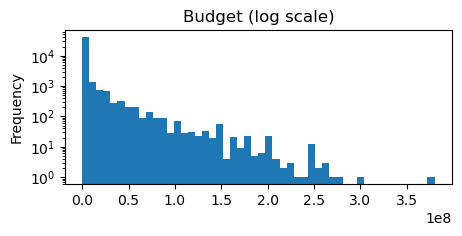

There are 0 (0.0%) columns with missing value for budget
There are 36573 (80.4%) columns with the value 0 for budget


In [19]:
display(mm.budget.describe())
# plot the budget
mm.budget.plot.hist(bins=50, figsize=(5, 2), title='Budget (log scale)', logy=True)
plt.show()

print(f"There are {mm.budget.isna().sum()} ({mm.budget.isna().mean():.1%}) columns with missing value for budget")
print(f"There are {mm[mm.budget == 0].shape[0]} ({mm[mm.budget == 0].shape[0]/mm.shape[0]:.1%}) columns with the value 0 for budget")

## revenue

count    4.546300e+04
mean     1.120861e+07
std      6.433019e+07
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.787965e+09
Name: revenue, dtype: float64

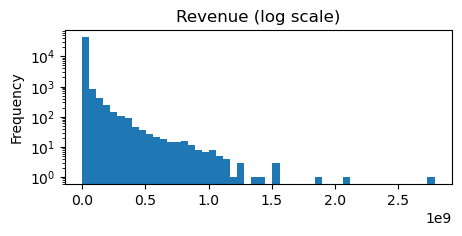

There are 0 (0.0%) columns with missing value for revenue
There are 38055 (83.7%) columns with the value 0 for revenue


In [20]:
display(mm.revenue.describe())

# revenue seems to be the correct type, but a lot of the rows are missing revenue value ...
# plot the revenue
mm.revenue.plot.hist(bins=50, figsize=(5, 2), title='Revenue (log scale)', logy=True)
plt.show()

print(f"There are {mm.revenue.isna().sum()} ({mm.revenue.isna().mean():.1%}) columns with missing value for revenue")
print(f"There are {mm[mm.revenue == 0].shape[0]} ({mm[mm.revenue == 0].shape[0]/mm.shape[0]:.1%}) columns with the value 0 for revenue")

## vote_average

count    45463.000000
mean         5.618217
std          1.924174
min          0.000000
25%          5.000000
50%          6.000000
75%          6.800000
max         10.000000
Name: vote_average, dtype: float64

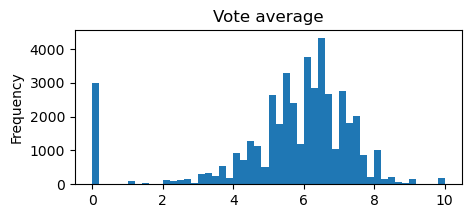

There are 0 (0.0%) columns with missing value for average vote
There are 2998 (6.6%) columns with the value 0 for average vote


In [21]:
display(mm.vote_average.describe())
# plot
mm.vote_average.plot.hist(bins=50, figsize=(5, 2), title='Vote average')
plt.show()

print(f"There are {mm.vote_average.isna().sum()} ({mm.vote_average.isna().mean():.1%}) columns with missing value for average vote")
print(f"There are {mm[mm.vote_average == 0].shape[0]} ({mm[mm.vote_average == 0].shape[0]/mm.shape[0]:.1%}) columns with the value 0 for average vote")

## vote_count

count    45463.000000
mean       109.890856
std        491.294816
min          0.000000
25%          3.000000
50%         10.000000
75%         34.000000
max      14075.000000
Name: vote_count, dtype: float64

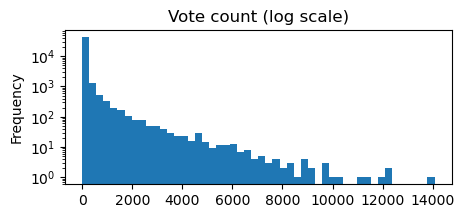

There are 0 (0.0%) columns with missing value for vote count
There are 2899 (6.4%) columns with the value 0 for vote count


In [22]:
display(mm.vote_count.describe())
# plot
mm.vote_count.plot.hist(bins=50, figsize=(5, 2), title='Vote count (log scale)', logy=True)
plt.show()

print(f"There are {mm.vote_count.isna().sum()} ({mm.vote_count.isna().mean():.1%}) columns with missing value for vote count")
print(f"There are {mm[mm.vote_count == 0].shape[0]} ({mm[mm.vote_count == 0].shape[0]/mm.shape[0]:.1%}) columns with the value 0 for vote count")

## genres

In [23]:
def explode(df, column_names):
    df_list = df.apply(ast.literal_eval) 
    exploded = df_list.explode().dropna()           
    df_exploded = pd.DataFrame()
    for column_name in column_names:
        df_exploded[column_name] = exploded.apply(lambda x: x[column_name])
    return df_exploded

# nr of rows without genres
print(f"Number of movies with no genre: {mm[mm.genres == '[]'].shape[0]} ({mm[mm.genres == '[]'].shape[0]/mm.shape[0]:.1%})")

# display the unique names
genres = explode(mm['genres'], ['id', 'name'])
display(genres.name.unique())

# check that the uniqueness of id
names_per_id = genres.groupby('id')['name'].nunique()
print(f"Nr of genres with multiple names per id: {names_per_id[names_per_id > 1].shape[0]}")
ids_per_name = genres.groupby('name')['id'].nunique()
print(f"Nr of genres with multiple ids per name: {ids_per_name[ids_per_name > 1].shape[0]}")


Number of movies with no genre: 2442 (5.4%)


array(['Animation', 'Comedy', 'Family', 'Adventure', 'Fantasy', 'Romance',
       'Drama', 'Action', 'Crime', 'Thriller', 'Horror', 'History',
       'Science Fiction', 'Mystery', 'War', 'Foreign', 'Music',
       'Documentary', 'Western', 'TV Movie'], dtype=object)

Nr of genres with multiple names per id: 0
Nr of genres with multiple ids per name: 0


## production companies

In [24]:
display(mm.production_companies.describe())
production_companies = explode(mm.production_companies, ['name', 'id'])

# check that the uniqueness of id
names_per_id = production_companies.groupby('id')['name'].nunique()
ids_per_name = production_companies.groupby('name')['id'].nunique()
print(f"Nr of production companies with multiple names per id: {names_per_id[names_per_id > 1].shape[0]}")
print(f"Nr of production companies with multiple ids per name: {ids_per_name[ids_per_name > 1].shape[0]}")

# display the names associated with multiple ids
names_with_multiple_ids = ids_per_name[ids_per_name > 1].index.unique()
display(production_companies[production_companies['name'].isin(names_with_multiple_ids)].drop_duplicates().sort_values(by=['name']))

print(f"There are {mm[mm.production_companies == '[]'].shape[0]} ({mm[mm.production_companies == '[]'].shape[0]/mm.shape[0]:.1%}) rows with missing value for production companies")

count     45463
unique    22710
top          []
freq      11875
Name: production_companies, dtype: object

Nr of production companies with multiple names per id: 0
Nr of production companies with multiple ids per name: 148


,name,id
13049,20th Century Fox Television,16323
10348,20th Century Fox Television,1556
64,3 Arts Entertainment,36390
1521,3 Arts Entertainment,787
6227,4 Kids Entertainment,34231
...,...,...
24495,Wigwam Films,55144
1165,Zoetrope Studios,26663
3956,Zoetrope Studios,13349
16864,Åke Lindman Film-Productions,95393


There are 11875 (26.1%) rows with missing value for production companies


## production countries

In [25]:
print(f"There are {mm[mm.production_countries == '[]'].shape[0]} ({mm[mm.production_countries == '[]'].shape[0]/mm.shape[0]:.1%}) rows with missing value for production countries")
production_countries = explode(mm.production_countries, ['name', 'iso_3166_1'])

# check that the uniqueness of iso
names_per_iso = production_countries.groupby('iso_3166_1')['name'].nunique()
iso_per_name = production_countries.groupby('name')['iso_3166_1'].nunique()
print(f"Nr of production countries with multiple names per iso: {names_per_iso[names_per_iso > 1].shape[0]}")
print(f"Nr of production countries with multiple iso per name: {iso_per_name[iso_per_name > 1].shape[0]}")

# display the names associated with multiple ids
names_with_multiple_iso = iso_per_name[iso_per_name > 1].index.unique()
display(production_countries[production_countries['name'].isin(names_with_multiple_iso)].drop_duplicates().sort_values(by=['name']))

There are 6282 (13.8%) rows with missing value for production countries
Nr of production countries with multiple names per iso: 0
Nr of production countries with multiple iso per name: 1


,name,iso_3166_1
751,Congo,CD
25023,Congo,CG


## spoken_languages

In [26]:
mm.spoken_languages.describe()
print(f"There are {mm[mm.spoken_languages == '[]'].shape[0]} ({mm[mm.spoken_languages == '[]'].shape[0]/mm.shape[0]:.1%}) rows with missing value for  spoken languages")
spoken_languages = explode(mm.spoken_languages, ['name', 'iso_639_1']).dropna()
display(spoken_languages.describe())

# display unique languages
display(spoken_languages['iso_639_1'].unique())

# nr of nan values
print(f"There are {spoken_languages.name.isna().sum()} rows with no value for name")
print(f"There are {spoken_languages.iso_639_1.isna().sum()} rows with no value for iso_639_1")

# check that the uniqueness of iso
names_per_iso = spoken_languages.groupby('iso_639_1')['name'].nunique()
iso_per_name = spoken_languages.groupby('name')['iso_639_1'].nunique()
print(f"Nr of spoken languages with multiple names per iso: {names_per_iso[names_per_iso > 1].shape[0]}")
print(f"Nr of spoken languages with multiple iso per name: {iso_per_name[iso_per_name > 1].shape[0]}")

# display the names associated with multiple ids, on inspection this is only nullvalues
names_with_multiple_iso = iso_per_name[iso_per_name > 1].index.unique()
print(f"There are {spoken_languages[spoken_languages['name'].isin(names_with_multiple_iso)].drop_duplicates().shape[0]} rows with missing name for spoken laguages")

There are 3829 (8.4%) rows with missing value for  spoken languages


,name,iso_639_1
count,53303,53303
unique,75,133
top,English,en
freq,28747,28747


array(['en', 'fr', 'es', 'de', 'ru', 'la', 'nl', 'cn', 'zh', 'hu', 'sq',
       'it', 'ko', 'fa', 'da', 'gd', 'ja', 'ar', 'hr', 'bs', 'mn', 'ro',
       'id', 'ms', 'mk', 'sv', 'he', 'kw', 'cs', 'nv', 'mi', 'tl', 'pl',
       'ga', 'no', 'sk', 'vi', 'yi', 'pt', 'hi', 'ca', 'is', 'af', 'sr',
       'bn', 'wo', 'cy', 'th', 'lv', 'sw', 'bg', 'el', 'ne', 'tr', 'km',
       'fi', 'eo', 'uk', 'iu', 'ka', 'sh', 'bo', 'nb', 'ty', 'xx', 'si',
       'as', 'gn', 'eu', 'az', 'mt', 'ur', 'zu', 'lo', 'xh', 'bm', 'cr',
       'ps', 'so', 'ku', 'hy', 'oc', 'pa', 'to', 'ce', 'qu', 'be', 'am',
       'tg', 'tt', 'se', 'ml', 'ta', 'co', 'gl', 'dz', 'rw', 'ht', 'kk',
       'ln', 'my', 'et', 'sa', 'lt', 'fy', 'tk', 'sl', 'te', 'ny', 'st',
       'sc', 'gu', 'ff', 'mr', 'ug', 'ay', 'ky', 'jv', 'br', 'sg', 'lb',
       'ab', 'kn', 'uz', 'sm', 'ki', 'tn', 'fo', 'sn', 'bi', 'ha', 'ig',
       'mh'], dtype=object)

There are 0 rows with no value for name
There are 0 rows with no value for iso_639_1
Nr of spoken languages with multiple names per iso: 0
Nr of spoken languages with multiple iso per name: 1
There are 59 rows with missing name for spoken laguages


## belongs_to_collection:

In [27]:
print(f"There are {mm[mm.belongs_to_collection.isna()].shape[0]} ({mm[mm.belongs_to_collection.isna()].shape[0]/mm.shape[0]:.1%}) rows with missing value for belongs to collection")

parsed = mm.belongs_to_collection.dropna().apply(ast.literal_eval)
belongs_to_collection = pd.DataFrame(parsed.tolist(), index=parsed.index)

# nr of nan values
print(f"There are {belongs_to_collection.name.isna().sum()} rows with no value for name")
print(f"There are {belongs_to_collection.id.isna().sum()} rows with no value for id")

# check that the uniqueness of ids
names_per_id = belongs_to_collection.groupby('id')['name'].nunique()
id_per_name = belongs_to_collection.groupby('name')['id'].nunique()
print(f"Nr of production countries with multiple names per id: {names_per_id[names_per_id > 1].shape[0]}")
print(f"Nr of production countries with multiple id per name: {id_per_name[id_per_name > 1].shape[0]}")

There are 40972 (90.1%) rows with missing value for belongs to collection
There are 0 rows with no value for name
There are 0 rows with no value for id
Nr of production countries with multiple names per id: 0
Nr of production countries with multiple id per name: 0


## adult

In [28]:
# since their does not appear to be many distinct values, we can display them all
display(mm.adult.value_counts())

# Conclusion: the three strange values, will be removed by removing the wrongfully displayed rows as they are discoevred earlier in the analysis

adult
False    45454
True         9
Name: count, dtype: int64

## original language

In [29]:
print(f"There are {mm[mm.original_language.isna()].shape[0]} ({mm[mm.original_language.isna()].shape[0]/mm.shape[0]:.1%}) rows with missing value for original language")

display(mm.original_language.describe())

# identify the unique since there are not that many
display(mm.original_language.unique())

# display the rows with the numbered values
#mm[mm.original_language.isin(['104.0', '68.0', '82.0'])]

# conclusion: the strange values will be removed, as they are identified earlier

There are 11 (0.0%) rows with missing value for original language


count     45452
unique       89
top          en
freq      32269
Name: original_language, dtype: object

array(['en', 'fr', 'zh', 'it', 'fa', 'nl', 'de', 'cn', 'ar', 'es', 'ru',
       'sv', 'ja', 'ko', 'sr', 'bn', 'he', 'pt', 'wo', 'ro', 'hu', 'cy',
       'vi', 'cs', 'da', 'no', 'nb', 'pl', 'el', 'sh', 'xx', 'mk', 'bo',
       'ca', 'fi', 'th', 'sk', 'bs', 'hi', 'tr', 'is', 'ps', 'ab', 'eo',
       'ka', 'mn', 'bm', 'zu', 'uk', 'af', 'la', 'et', 'ku', 'fy', 'lv',
       'ta', 'sl', 'tl', 'ur', 'rw', 'id', 'bg', 'mr', 'lt', 'kk', 'ms',
       'sq', nan, 'qu', 'te', 'am', 'jv', 'tg', 'ml', 'hr', 'lo', 'ay',
       'kn', 'eu', 'ne', 'pa', 'ky', 'gl', 'uz', 'sm', 'mt', 'hy', 'iu',
       'lb', 'si'], dtype=object)

## popularity

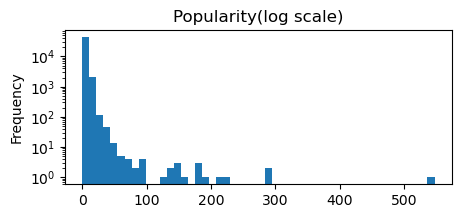

There are 0 (0.0%) columns with missing value for popularity
There are 66 (0.1%) columns with the value 0 for popularity


In [30]:
mm.popularity.describe()

# plot
mm.popularity.plot.hist(bins=50, figsize=(5, 2), title='Popularity(log scale)', logy=True)
plt.show()

print(f"There are {mm.popularity.isna().sum()} ({mm.popularity.isna().mean():.1%}) columns with missing value for popularity")
print(f"There are {mm[mm.popularity == 0].shape[0]} ({mm[mm.popularity == 0].shape[0]/mm.shape[0]:.1%}) columns with the value 0 for popularity")

## imdb_id

In [31]:
mm.imdb_id.describe()

# check whether id is unique
imdb_id_vc = mm.imdb_id.value_counts()
print(f'There are {mm.imdb_id.shape[0] - len(mm.imdb_id.unique())} duplicate rows, among which the highest number of duplicates for one id is {imdb_id_vc.values[0].item()} which occurs {(imdb_id_vc == imdb_id_vc.iloc[0]).sum().item()} time ')
print(f"Nr of rows with no id: {mm[mm.imdb_id.isna()].shape[0]}")


duplicate_ids = get_duplicates(mm, 'imdb_id')
column_differs(duplicate_ids, 'imdb_id')

# Conclusion it appears af is the only duplicate rows that are not already fonud are the one with a zero value for imdb_id

There are 46 duplicate rows, among which the highest number of duplicates for one id is 3 which occurs 1 time 
Nr of rows with no id: 17
Fully identical duplicates: 16 of 29


popularity    13
vote_count     2
Name: differing_columns, dtype: int64

##status

In [32]:
mm.status.value_counts()

status
Released           45017
Rumored              230
Post Production       98
In Production         20
Planned               15
Canceled               2
Name: count, dtype: int64

## tagline

In [33]:
def discover_strings(df_column, name):
    print(f"Nr of rows with no {name}: {df_column.isna().sum()} ({df_column.isna().mean():.1%})")
    
    # discover formatting errors
    c = df_column.dropna()
    print("Nr of rows containing leading/trailing spaces:", (c != c.str.strip()).sum())
    print("Nr of rows containing double spaces:", c.str.contains('  ').sum())
    print("Nr of rows containing line breaks:", c.str.contains(r'[\n\r\t]').sum())

    # placeholder-like values (very short)
    lengths = c.str.len()
    print(f"Values for {name} that are shorter than 4 characters:")
    display(c[lengths < 4].value_counts(dropna=False))

    # most frequent
    print(f"The most frequent values for {name}:")
    display(c.value_counts().head(5))

discover_strings(mm.tagline, "tagline")
# taglines that just repeat another column
print("Nr of tagline identical to title:", (mm.tagline == mm.title).sum())
print("Nr of tagline identical to overview:", (mm.tagline == mm.overview).sum())


Nr of rows with no tagline: 25050 (55.1%)
Nr of rows containing leading/trailing spaces: 1
Nr of rows containing double spaces: 113
Nr of rows containing line breaks: 0
Values for tagline that are shorter than 4 characters:


tagline
-      4
       1
Go!    1
B&W    1
To     1
Run    1
Name: count, dtype: int64

The most frequent values for tagline:


tagline
Based on a true story.           7
Be careful what you wish for.    4
Trust no one.                    4
-                                4
Drama                            3
Name: count, dtype: int64

Nr of tagline identical to title: 50
Nr of tagline identical to overview: 37


## video

In [34]:
mm.video.value_counts()

video
False    45370
True        93
Name: count, dtype: int64

## overview

In [35]:
discover_strings(mm.overview, "overview")
# taglines that just repeat another column
print("Nr of overview identical to title:", (mm.overview == mm.title).sum())


Nr of rows with no overview: 954 (2.1%)
Nr of rows containing leading/trailing spaces: 8
Nr of rows containing double spaces: 1348
Nr of rows containing line breaks: 74
Values for overview that are shorter than 4 characters:


overview
       5
...    1
x      1
Name: count, dtype: int64

The most frequent values for overview:


overview
No overview found.                                                                                                                                                        133
No Overview                                                                                                                                                                 7
                                                                                                                                                                            5
Recovering from a nail gun shot to the head and 13 months of coma, doctor Pekka Valinta starts to unravel the mystery of his past, still suffering from total amnesia.      3
Adaptation of the Jane Austen novel.                                                                                                                                        3
Name: count, dtype: int64

Nr of overview identical to title: 12


## Findings and decisions

| Finding | Decision |
|---|---|
|There were three records with line breaks inside `overview`, which lead to six lines when loading the csv with default reader. | Load the file manually to handle line breaks|
|There are 45,463 rows and 24 columns|No action needed|
|`id` has no missing values, but is not unique. 29 ids occur more than once, where 16 are copies and the remaining 13 differ in `popularity` and `vote_count`. The higher indexes had a higher `vote_count`, where it differed, which could indicate that the last row contains more information| We therefore decided to keep the last occurence|
|`title` has 22 rows containing double spaces, and 50 rows that differ by case|Remove double spaces|
|`title` (42,279 unique) and `original_title` (43,371 unique) are not unique. Repeated titles are mostly different movies, e.g. *Cinderella* appears 11 times with different release dates|No action needed|
|`release_date` ranges from 1874 to 2020|No action needed, but this can explain why there are a lot of missing values for some columns, as all the information might not have beeen stored.|
|There are a lot of columns with a high percentage of null values, such as `budget`, `belongs_to_collection`, `revenue`, `tagline`|`budget` and `revenue` needs to be converted to `null` values to avoid affecting average in queries. `runtime` and `vote_count` where `vote_average`==0 should also have `null`values instead of 0 values to avoid affecting average analysis.   `belongs_to_collection` will be stored as a separate collection, due to the high amount of missing values and as it will make queries easier|
|The median `vote_count` is only 10, while the max is 14075.0 so `vote_average` is unreliable for many movies|No action needed|
|For `production_companies`, each id has one name, but 148 names map to several ids|Keep the last id and map all the others to this id. The last is probably the most recent and the others could simply be stale values|
|For `production_countries` only *Congo* maps to two codes, `CD` and `CG`. These are two real, different countries|No action needed|
|In `spoken_languages` there 133 codes but only 75 names, because 59 codes have an empty name|Only keep the names|
|`imdb_id` has 17 missing values, and its duplicates are the same 29 movies as for `id`|No action needed|
|`tagline` is missing for 55.1 % of the movies. Among the 20,413 that have one, there are 113 with double spaces and 1 with leading/trailing whitespace. Some are placeholders rather than real taglines: `-`, `""`. 50 taglines are identical to the movie's title and 37 to its overview.|Replace the rows with only the value `-` with `NaN`. Remove whitespace and double spaces. Replace "" with `Nan` values.Replace title and overview values with NaN values as it does not provide any more information|
|`overview` has 1348 rows containing doyble spaces and 74 rows containing line breaks. Further, the following values that are not meaningful: `""`,`...`, `x`,`No overview found`, `No Overview`. 5 rows have overview identical to title|Remove those values without meaning and fix the strings by removing double spaces etc. Replace title values with NaN values as it does not provide any more information|
|There are 20 genres with a one-to-one id to name mapping|Only keep the name of the genres|


**Missing values (often hidden as `0` or `[]`)**

| Column | Encoded as | Rows |
|---|---|---|
| `budget` | `0` | 36,573 (80.4 %) |
| `belongs_to_collection` | `NaN` | 40,972 (90.1%) |
| `revenue` | `0` | 38,055 (83.7 %) |
| `runtime` | `NaN` / `0` | 257 (0.6%) / 1,558 (3.4%)|
| `vote_count` & `vote_average` | both `0` | 2,899 (6.4%)|
| `release_date` | `NaN` | 84 (0.2 %)|
| `original_language` | `NaN` | 11 (0.0 %) |
| `overview` | `NaN` | 954 (2.1 %) |
| `tagline` | `NaN` | 25,050 (55.1 %) |
| `genres` | `[]` | 2,442 (5.4 %) |
| `popularity` | `0` | 66 (0.1%) |
| `production_companies` | `[]` | 11,875 (26.1%)|
| `production_countries` | `[]` | 6,282 (13.8%) |
| `spoken_languages` | `[]` | 3,829 (8.4%)|

**Not examined:** `homepage` and `poster_path` as they were not relevant to the analysis.
